In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
prototxt_path = "models/models_colorization_deploy_v2.prototxt"
model_path = "models/colorization_release_v2.caffemodel"
points_path = "models/pts_in_hull.npy"

print("Prototxt exists:", os.path.exists(prototxt_path))
print("Model exists:", os.path.exists(model_path))
print("Points file exists:", os.path.exists(points_path))

Prototxt exists: True
Model exists: True
Points file exists: True


In [4]:
net = cv2.dnn.readNetFromCaffe(prototxt_path, model_path)
pts = np.load(points_path)

class8 = net.getLayerId("class8_ab")
conv8 = net.getLayerId("conv8_313_rh")

pts = pts.transpose().reshape(2, 313, 1, 1)

net.getLayer(class8).blobs = [
    pts.astype("float32")
]

net.getLayer(conv8).blobs = [
    np.full([1, 313], 2.606, dtype="float32")
]

print("Colorization model loaded successfully.")

Colorization model loaded successfully.


In [5]:
def colorize_image(image_path):
    """
    Colorize an input image using the pretrained Zhang et al.
    image colorization model.

    Parameters
    ----------
    image_path : str
        Path to the input image.

    Returns
    -------
    original_rgb : numpy.ndarray
        Original image in RGB format.

    grayscale_rgb : numpy.ndarray
        Grayscale version displayed in RGB format.

    colorized_rgb : numpy.ndarray
        Colorized output image in RGB format.
    """

    # Read image using OpenCV
    image_bgr = cv2.imread(image_path)

    if image_bgr is None:
        raise FileNotFoundError(
            f"Could not read the image: {image_path}"
        )

    # Convert original image to RGB for displaying
    original_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    # Convert input image to grayscale
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # Convert grayscale image back to BGR
    gray_bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    # Convert BGR image to RGB
    gray_rgb = cv2.cvtColor(gray_bgr, cv2.COLOR_BGR2RGB)

    # Normalize pixel values to 0–1
    scaled = gray_rgb.astype("float32") / 255.0

    # Convert RGB image into Lab colour space
    lab = cv2.cvtColor(scaled, cv2.COLOR_RGB2LAB)

    # Resize image to model input size
    resized = cv2.resize(lab, (224, 224))

    # Extract L channel
    L = cv2.split(resized)[0]

    # Mean-centre the L channel
    L -= 50

    # Send L channel through the neural network
    net.setInput(cv2.dnn.blobFromImage(L))

    # Predict a and b colour channels
    ab = net.forward()[0, :, :, :].transpose((1, 2, 0))

    # Resize predicted colour channels to original size
    ab = cv2.resize(
        ab,
        (gray_rgb.shape[1], gray_rgb.shape[0])
    )

    # Get original-resolution L channel
    original_L = cv2.split(lab)[0]

    # Combine L, a and b channels
    colorized_lab = np.concatenate(
        (
            original_L[:, :, np.newaxis],
            ab
        ),
        axis=2
    )

    # Convert Lab image back to RGB
    colorized_rgb = cv2.cvtColor(
        colorized_lab,
        cv2.COLOR_LAB2RGB
    )

    # Restrict values to 0–1
    colorized_rgb = np.clip(colorized_rgb, 0, 1)

    # Convert to unsigned 8-bit image
    colorized_rgb = (
        colorized_rgb * 255
    ).astype("uint8")

    return original_rgb, gray_rgb, colorized_rgb

In [6]:
os.listdir("Input_images")

['img1.jpg',
 'pexels-pixabay-36755.jpg',
 'monalisa.jpeg',
 'pexels-pixabay-141651.jpg']

In [7]:
input_path = "Input_images/img1.jpg"

original, grayscale, colorized = colorize_image(input_path)

print("Image colorized successfully.")

Image colorized successfully.


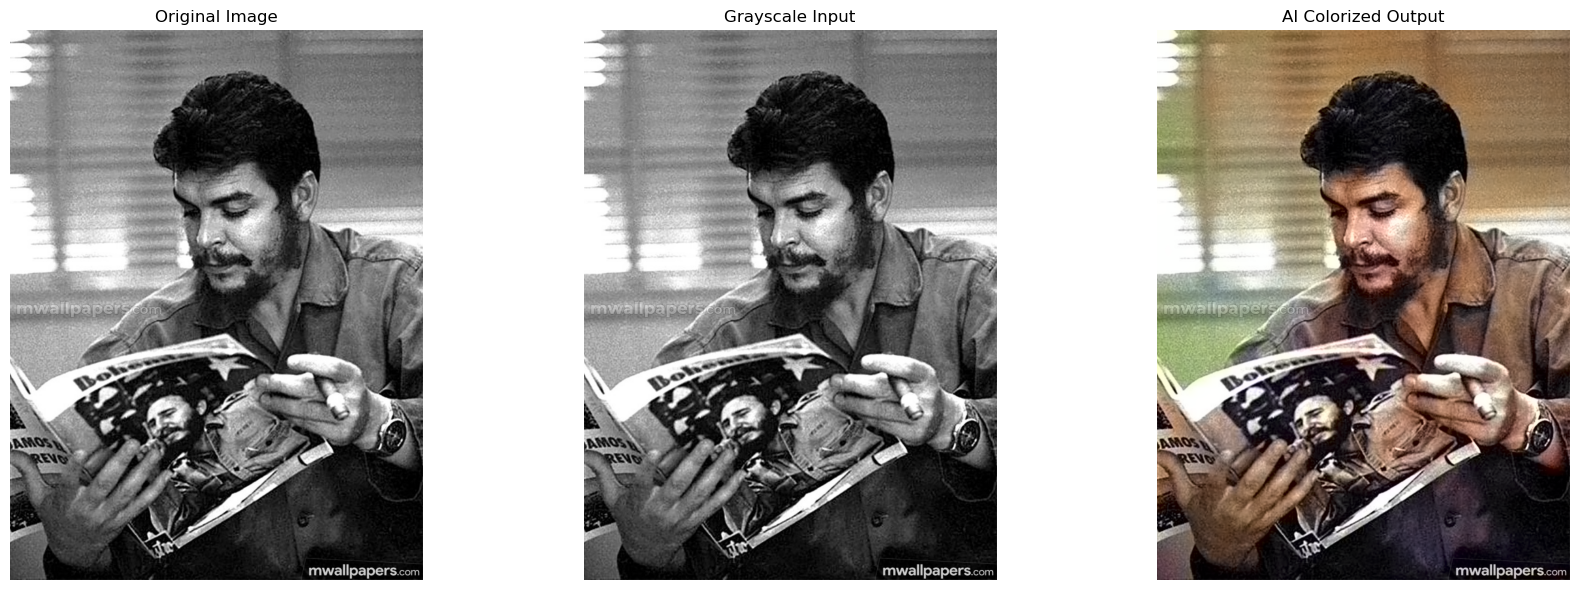

In [8]:
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale, cmap="gray")
plt.title("Grayscale Input")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(colorized)
plt.title("AI Colorized Output")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
output_path = "Result_images/notebook_colorized_output.jpg"

# OpenCV saves images in BGR format
colorized_bgr = cv2.cvtColor(
    colorized,
    cv2.COLOR_RGB2BGR
)

saved = cv2.imwrite(
    output_path,
    colorized_bgr
)

if saved:
    print("Saved successfully:", output_path)
else:
    print("Failed to save the image.")

Saved successfully: Result_images/notebook_colorized_output.jpg


In [10]:
input_path = "Input_images/monalisa.jpeg"

original, grayscale, colorized = colorize_image(input_path)

print("Image colorized successfully.")

Image colorized successfully.


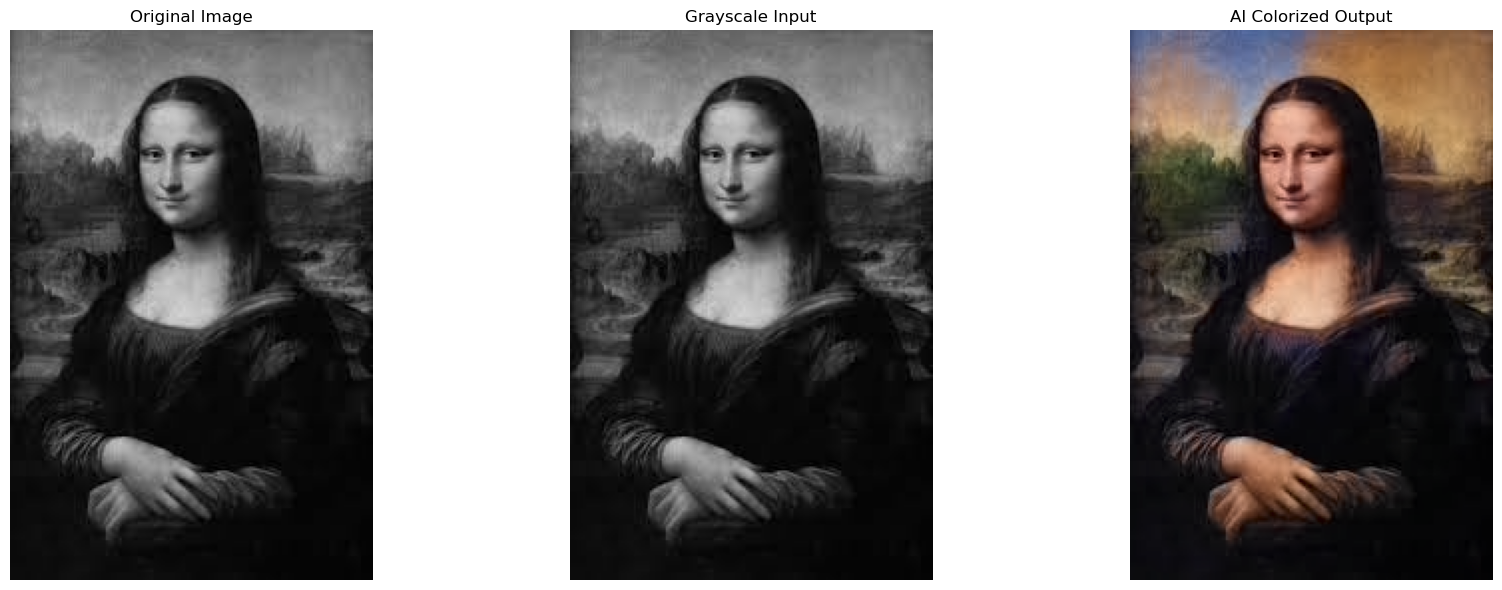

In [11]:
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale, cmap="gray")
plt.title("Grayscale Input")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(colorized)
plt.title("AI Colorized Output")
plt.axis("off")

plt.tight_layout()
plt.show()